# Notebook 05 – IndiaPII Model Comparison and Evaluation

**Environment:** Local VS Code / Python 3.11  
**Models:** Regex baseline, Presidio baseline, fine-tuned MuRIL

This notebook consolidates the actual baseline CSV results uploaded from Notebook 02 and the MuRIL metrics reported after Notebook 03.

**Evaluation basis:** exact-span entity-level metrics over the 140-sample test set (entity supports: PERSON 40, ADDRESS 20, PHONE 40, AADHAAR 40, PAN 20, EMAIL 20, UPI 40). Language supports: English 40, Hindi 60, Hinglish 40.

**Important:** MuRIL metrics below are entered from the evaluation output shared for Notebook 03. Baseline metrics are read from the uploaded Notebook 02 result CSVs and embedded below for reproducibility. This notebook does not retrain models or regenerate baseline predictions.


In [2]:
# Cell 1 – Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

print("Notebook 05 – IndiaPII model comparison")


Matplotlib is building the font cache; this may take a moment.


Notebook 05 – IndiaPII model comparison


In [3]:
# Cell 2 – Load actual Regex and Presidio baseline metrics
# Values transcribed directly from the uploaded Notebook 02 result CSV files.
baseline_entity_rows = [
  {
    "Entity": "PERSON",
    "Regex Precision": 0.0,
    "Regex Recall": 0.0,
    "Regex F1": 0.0,
    "Presidio Precision": 0.3415,
    "Presidio Recall": 0.35,
    "Presidio F1": 0.3457,
    "Support": 40
  },
  {
    "Entity": "ADDRESS",
    "Regex Precision": 0.0,
    "Regex Recall": 0.0,
    "Regex F1": 0.0,
    "Presidio Precision": 0.0,
    "Presidio Recall": 0.0,
    "Presidio F1": 0.0,
    "Support": 20
  },
  {
    "Entity": "PHONE",
    "Regex Precision": 1.0,
    "Regex Recall": 1.0,
    "Regex F1": 1.0,
    "Presidio Precision": 1.0,
    "Presidio Recall": 1.0,
    "Presidio F1": 1.0,
    "Support": 40
  },
  {
    "Entity": "AADHAAR",
    "Regex Precision": 1.0,
    "Regex Recall": 1.0,
    "Regex F1": 1.0,
    "Presidio Precision": 1.0,
    "Presidio Recall": 1.0,
    "Presidio F1": 1.0,
    "Support": 40
  },
  {
    "Entity": "PAN",
    "Regex Precision": 1.0,
    "Regex Recall": 1.0,
    "Regex F1": 1.0,
    "Presidio Precision": 1.0,
    "Presidio Recall": 1.0,
    "Presidio F1": 1.0,
    "Support": 20
  },
  {
    "Entity": "EMAIL",
    "Regex Precision": 1.0,
    "Regex Recall": 1.0,
    "Regex F1": 1.0,
    "Presidio Precision": 1.0,
    "Presidio Recall": 1.0,
    "Presidio F1": 1.0,
    "Support": 20
  },
  {
    "Entity": "UPI",
    "Regex Precision": 1.0,
    "Regex Recall": 1.0,
    "Regex F1": 1.0,
    "Presidio Precision": 1.0,
    "Presidio Recall": 1.0,
    "Presidio F1": 1.0,
    "Support": 40
  }
]

baseline_entity_df = pd.DataFrame(baseline_entity_rows)
display(baseline_entity_df)


,Entity,Regex Precision,Regex Recall,Regex F1,Presidio Precision,Presidio Recall,Presidio F1,Support
0,PERSON,0.0,0.0,0.0,0.3415,0.35,0.3457,40
1,ADDRESS,0.0,0.0,0.0,0.0000,0.00,0.0000,20
2,PHONE,1.0,1.0,1.0,1.0000,1.00,1.0000,40
3,AADHAAR,1.0,1.0,1.0,1.0000,1.00,1.0000,40
4,PAN,1.0,1.0,1.0,1.0000,1.00,1.0000,20
5,EMAIL,1.0,1.0,1.0,1.0000,1.00,1.0000,20
6,UPI,1.0,1.0,1.0,1.0000,1.00,1.0000,40


In [4]:
# Cell 3 – Add MuRIL entity-wise metrics from Notebook 03 output
muril_entity_rows = [
    {"Entity": "PERSON",  "MuRIL Precision": 1.0000, "MuRIL Recall": 1.0000, "MuRIL F1": 1.0000, "Support": 40},
    {"Entity": "ADDRESS", "MuRIL Precision": 1.0000, "MuRIL Recall": 1.0000, "MuRIL F1": 1.0000, "Support": 20},
    {"Entity": "PHONE",   "MuRIL Precision": 1.0000, "MuRIL Recall": 1.0000, "MuRIL F1": 1.0000, "Support": 40},
    {"Entity": "AADHAAR", "MuRIL Precision": 1.0000, "MuRIL Recall": 1.0000, "MuRIL F1": 1.0000, "Support": 40},
    {"Entity": "PAN",     "MuRIL Precision": 0.9091, "MuRIL Recall": 1.0000, "MuRIL F1": 0.9524, "Support": 20},
    {"Entity": "EMAIL",   "MuRIL Precision": 1.0000, "MuRIL Recall": 1.0000, "MuRIL F1": 1.0000, "Support": 20},
    {"Entity": "UPI",     "MuRIL Precision": 1.0000, "MuRIL Recall": 1.0000, "MuRIL F1": 1.0000, "Support": 40},
]
muril_entity_df = pd.DataFrame(muril_entity_rows)
display(muril_entity_df)


,Entity,MuRIL Precision,MuRIL Recall,MuRIL F1,Support
0,PERSON,1.0000,1.0,1.0000,40
1,ADDRESS,1.0000,1.0,1.0000,20
2,PHONE,1.0000,1.0,1.0000,40
3,AADHAAR,1.0000,1.0,1.0000,40
4,PAN,0.9091,1.0,0.9524,20
5,EMAIL,1.0000,1.0,1.0000,20
6,UPI,1.0000,1.0,1.0000,40


In [5]:
# Cell 4 – Consolidated entity-wise comparison
entity_comparison = baseline_entity_df.merge(
    muril_entity_df[["Entity", "MuRIL Precision", "MuRIL Recall", "MuRIL F1"]],
    on="Entity",
    how="left"
)
display(entity_comparison)


,Entity,Regex Precision,Regex Recall,Regex F1,Presidio Precision,Presidio Recall,Presidio F1,Support,MuRIL Precision,MuRIL Recall,MuRIL F1
0,PERSON,0.0,0.0,0.0,0.3415,0.35,0.3457,40,1.0000,1.0,1.0000
1,ADDRESS,0.0,0.0,0.0,0.0000,0.00,0.0000,20,1.0000,1.0,1.0000
2,PHONE,1.0,1.0,1.0,1.0000,1.00,1.0000,40,1.0000,1.0,1.0000
3,AADHAAR,1.0,1.0,1.0,1.0000,1.00,1.0000,40,1.0000,1.0,1.0000
4,PAN,1.0,1.0,1.0,1.0000,1.00,1.0000,20,0.9091,1.0,0.9524
5,EMAIL,1.0,1.0,1.0,1.0000,1.00,1.0000,20,1.0000,1.0,1.0000
6,UPI,1.0,1.0,1.0,1.0000,1.00,1.0000,40,1.0000,1.0,1.0000


In [6]:
# Cell 5 – Language-wise baseline results from Notebook 02
regex_language_df = pd.DataFrame([
  {
    "Language": "en",
    "Entity": "PERSON",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 20
  },
  {
    "Language": "en",
    "Entity": "ADDRESS",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "en",
    "Entity": "PHONE",
    "Precision": 1.0,
    "Recall": 1.0,
    "F1-score": 1.0,
    "Support": 40
  },
  {
    "Language": "en",
    "Entity": "AADHAAR",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "en",
    "Entity": "PAN",
    "Precision": 1.0,
    "Recall": 1.0,
    "F1-score": 1.0,
    "Support": 20
  },
  {
    "Language": "en",
    "Entity": "EMAIL",
    "Precision": 1.0,
    "Recall": 1.0,
    "F1-score": 1.0,
    "Support": 20
  },
  {
    "Language": "en",
    "Entity": "UPI",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hi",
    "Entity": "PERSON",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hi",
    "Entity": "ADDRESS",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 20
  },
  {
    "Language": "hi",
    "Entity": "PHONE",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hi",
    "Entity": "AADHAAR",
    "Precision": 1.0,
    "Recall": 1.0,
    "F1-score": 1.0,
    "Support": 40
  },
  {
    "Language": "hi",
    "Entity": "PAN",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hi",
    "Entity": "EMAIL",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hi",
    "Entity": "UPI",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "PERSON",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 20
  },
  {
    "Language": "hinglish",
    "Entity": "ADDRESS",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "PHONE",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "AADHAAR",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "PAN",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "EMAIL",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "UPI",
    "Precision": 1.0,
    "Recall": 1.0,
    "F1-score": 1.0,
    "Support": 40
  }
])
presidio_language_df = pd.DataFrame([
  {
    "Language": "en",
    "Entity": "PERSON",
    "Precision": 1.0,
    "Recall": 0.6,
    "F1-score": 0.75,
    "Support": 20
  },
  {
    "Language": "en",
    "Entity": "ADDRESS",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "en",
    "Entity": "PHONE",
    "Precision": 1.0,
    "Recall": 1.0,
    "F1-score": 1.0,
    "Support": 40
  },
  {
    "Language": "en",
    "Entity": "AADHAAR",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "en",
    "Entity": "PAN",
    "Precision": 1.0,
    "Recall": 1.0,
    "F1-score": 1.0,
    "Support": 20
  },
  {
    "Language": "en",
    "Entity": "EMAIL",
    "Precision": 1.0,
    "Recall": 1.0,
    "F1-score": 1.0,
    "Support": 20
  },
  {
    "Language": "en",
    "Entity": "UPI",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hi",
    "Entity": "PERSON",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hi",
    "Entity": "ADDRESS",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 20
  },
  {
    "Language": "hi",
    "Entity": "PHONE",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hi",
    "Entity": "AADHAAR",
    "Precision": 1.0,
    "Recall": 1.0,
    "F1-score": 1.0,
    "Support": 40
  },
  {
    "Language": "hi",
    "Entity": "PAN",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hi",
    "Entity": "EMAIL",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hi",
    "Entity": "UPI",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "PERSON",
    "Precision": 0.0714,
    "Recall": 0.1,
    "F1-score": 0.0833,
    "Support": 20
  },
  {
    "Language": "hinglish",
    "Entity": "ADDRESS",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "PHONE",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "AADHAAR",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "PAN",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "EMAIL",
    "Precision": 0.0,
    "Recall": 0.0,
    "F1-score": 0.0,
    "Support": 0
  },
  {
    "Language": "hinglish",
    "Entity": "UPI",
    "Precision": 1.0,
    "Recall": 1.0,
    "F1-score": 1.0,
    "Support": 40
  }
])

baseline_language_df = regex_language_df.merge(
    presidio_language_df,
    on=["Language", "Entity", "Support"],
    suffixes=("_Regex", "_Presidio"),
    how="outer"
)
display(baseline_language_df)


,Language,Entity,Precision_Regex,Recall_Regex,F1-score_Regex,Support,Precision_Presidio,Recall_Presidio,F1-score_Presidio
0,en,AADHAAR,0.0,0.0,0.0,0,0.0000,0.0,0.0000
1,en,ADDRESS,0.0,0.0,0.0,0,0.0000,0.0,0.0000
2,en,EMAIL,1.0,1.0,1.0,20,1.0000,1.0,1.0000
3,en,PAN,1.0,1.0,1.0,20,1.0000,1.0,1.0000
4,en,PERSON,0.0,0.0,0.0,20,1.0000,0.6,0.7500
5,en,PHONE,1.0,1.0,1.0,40,1.0000,1.0,1.0000
6,en,UPI,0.0,0.0,0.0,0,0.0000,0.0,0.0000
7,hi,AADHAAR,1.0,1.0,1.0,40,1.0000,1.0,1.0000
8,hi,ADDRESS,0.0,0.0,0.0,20,0.0000,0.0,0.0000
9,hi,EMAIL,0.0,0.0,0.0,0,0.0000,0.0,0.0000


In [7]:
# Cell 6 – MuRIL language-wise metrics from Notebook 03 output
muril_language_df = pd.DataFrame([
    {"Language": "en", "Support": 40, "MuRIL Precision": 0.9804, "MuRIL Recall": 1.0000, "MuRIL F1": 0.9901},
    {"Language": "hi", "Support": 60, "MuRIL Precision": 1.0000, "MuRIL Recall": 1.0000, "MuRIL F1": 1.0000},
    {"Language": "hinglish", "Support": 40, "MuRIL Precision": 1.0000, "MuRIL Recall": 1.0000, "MuRIL F1": 1.0000},
])
display(muril_language_df)


,Language,Support,MuRIL Precision,MuRIL Recall,MuRIL F1
0,en,40,0.9804,1.0,0.9901
1,hi,60,1.0000,1.0,1.0000
2,hinglish,40,1.0000,1.0,1.0000


,Model,Macro F1
0,Regex,0.714286
1,Presidio,0.763671
2,MuRIL,0.993200


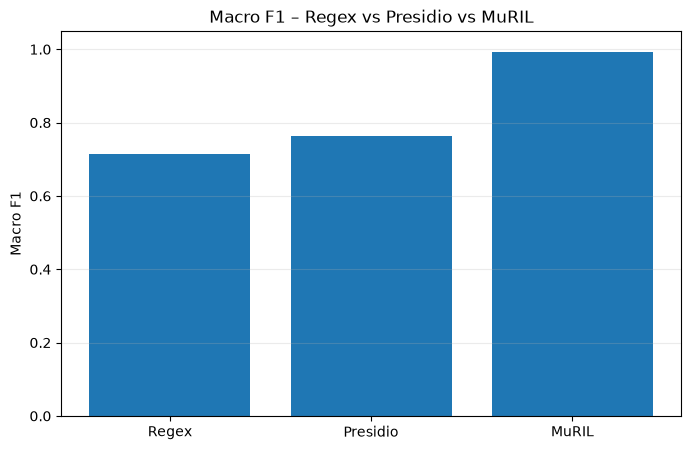

In [8]:
# Cell 7 – Macro F1 comparison
# Baseline macro F1 values are the mean of the seven entity-wise F1 scores.
macro_f1_df = pd.DataFrame([
    {"Model": "Regex", "Macro F1": baseline_entity_df["Regex F1"].mean()},
    {"Model": "Presidio", "Macro F1": baseline_entity_df["Presidio F1"].mean()},
    {"Model": "MuRIL", "Macro F1": muril_entity_df["MuRIL F1"].mean()},
])
display(macro_f1_df)

plt.figure(figsize=(8, 5))
plt.bar(macro_f1_df["Model"], macro_f1_df["Macro F1"])
plt.ylim(0, 1.05)
plt.ylabel("Macro F1")
plt.title("Macro F1 – Regex vs Presidio vs MuRIL")
plt.grid(axis="y", alpha=0.25)
plt.show()


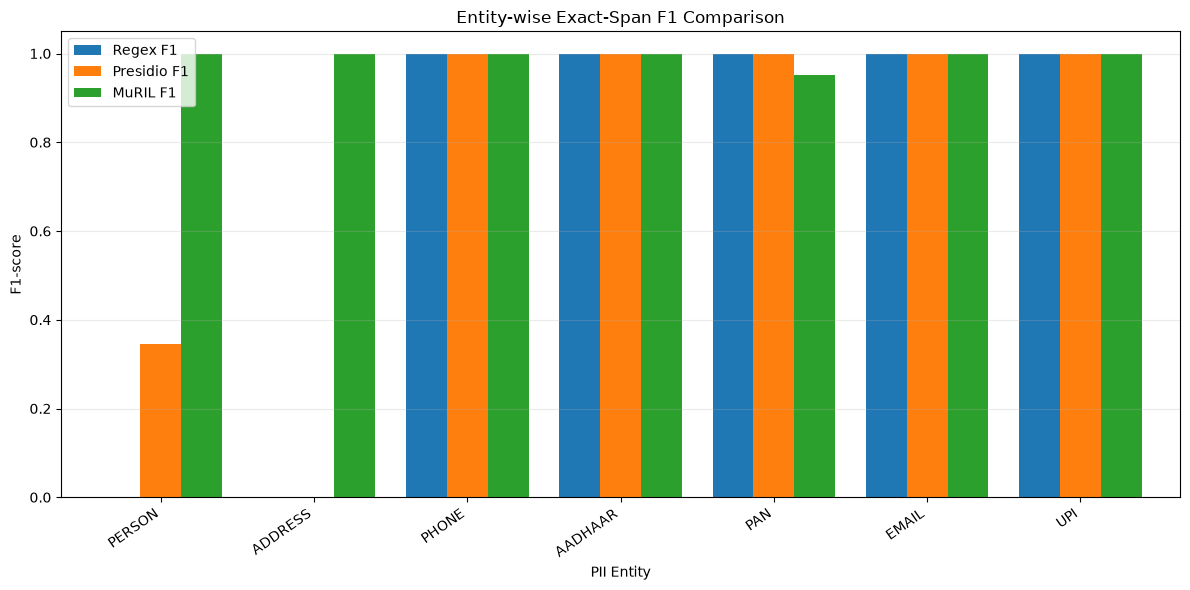

In [9]:
# Cell 8 – Entity-wise F1 comparison
plot_df = entity_comparison.set_index("Entity")[["Regex F1", "Presidio F1", "MuRIL F1"]]
ax = plot_df.plot(kind="bar", figsize=(12, 6), ylim=(0, 1.05), width=0.8)
ax.set_ylabel("F1-score")
ax.set_title("Entity-wise Exact-Span F1 Comparison")
ax.set_xlabel("PII Entity")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [10]:
# Cell 9 – Language-wise F1 comparison
language_comparison = muril_language_df[["Language", "MuRIL F1"]].copy()

# Baseline language-level F1: aggregate entity-level TP/FP/FN is not present in the CSV.
# Therefore, do not average rows with zero support or claim this is a micro score.
# The uploaded language CSVs are retained for detailed entity-language inspection.
print("MuRIL language-wise results:")
display(language_comparison)
print("\\nBaseline language-wise results (entity by language):")
display(baseline_language_df[["Language", "Entity", "F1-score_Regex", "F1-score_Presidio", "Support"]])


MuRIL language-wise results:


,Language,MuRIL F1
0,en,0.9901
1,hi,1.0000
2,hinglish,1.0000


\nBaseline language-wise results (entity by language):


,Language,Entity,F1-score_Regex,F1-score_Presidio,Support
0,en,AADHAAR,0.0,0.0000,0
1,en,ADDRESS,0.0,0.0000,0
2,en,EMAIL,1.0,1.0000,20
3,en,PAN,1.0,1.0000,20
4,en,PERSON,0.0,0.7500,20
5,en,PHONE,1.0,1.0000,40
6,en,UPI,0.0,0.0000,0
7,hi,AADHAAR,1.0,1.0000,40
8,hi,ADDRESS,0.0,0.0000,20
9,hi,EMAIL,0.0,0.0000,0


## Interpretation and limitations

- Regex and Presidio achieve perfect scores on several structured formats in this synthetic test set, including PHONE, AADHAAR, PAN, EMAIL and UPI.
- Regex has zero PERSON and ADDRESS F1 in the uploaded entity-wise results.
- Presidio has PERSON F1 = 0.3457 and ADDRESS F1 = 0.0000 in the uploaded results.
- MuRIL reports high entity-wise F1 across all seven labels, with PAN F1 = 0.9524; its language-wise F1 is 0.9901 for English and 1.0000 for Hindi and Hinglish.
- The MuRIL language-wise support is 40/60/40. Entity support is 40/20/40/40/20/20/40.
- These results are from a small synthetic dataset. They should not be presented as real-world generalization performance.
- The baseline language CSVs report rows with zero support as zero-valued metrics. Interpret those rows as no gold examples for that language/entity combination, not as meaningful evidence of model failure.
- The baseline CSVs do not contain the per-language aggregate TP/FP/FN counts needed to calculate a defensible language-level micro F1 for Regex and Presidio. This notebook therefore shows their language-by-entity F1 values instead of inventing an aggregate.


In [11]:
# Cell 10 – Save consolidated comparison tables
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

OUTPUT_DIR = PROJECT_ROOT / "results" / "comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

entity_comparison.to_csv(OUTPUT_DIR / "entity_model_comparison.csv", index=False)
muril_language_df.to_csv(OUTPUT_DIR / "muril_language_metrics.csv", index=False)
baseline_language_df.to_csv(OUTPUT_DIR / "baseline_language_entity_metrics.csv", index=False)
macro_f1_df.to_csv(OUTPUT_DIR / "macro_f1_comparison.csv", index=False)

print("Saved comparison outputs to:", OUTPUT_DIR)
print("Files:")
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", file.name)


Saved comparison outputs to: /Users/navyaa09/IndiaPII/results/comparison
Files:
 - baseline_language_entity_metrics.csv
 - entity_model_comparison.csv
 - macro_f1_comparison.csv
 - muril_language_metrics.csv


## Notebook 05 completion checklist

- [ ] Entity-wise Regex, Presidio and MuRIL metrics reviewed
- [ ] Macro F1 comparison reviewed
- [ ] Entity-wise F1 chart reviewed
- [ ] Language-wise results reviewed without treating zero-support rows as real failures
- [ ] CSV comparison outputs saved under `results/comparison/`

**Next project stage:** integrate the fine-tuned MuRIL detector and reversible masking module into the FastAPI backend, then build the Streamlit interface.
